# Madhava-Leibniz π calculation
#### Chenfan Li

## Problem

The Madhava-Leibniz series estimates π with alternating fractions:

$$
\pi \approx 4\left(1-\frac{1}{3}+\frac{1}{5}-\frac{1}{7}+\frac{1}{9}-\cdots\right)
$$

I modified the lecture example to save the approximation at every iteration and calculate absolute error. I then used the stored results to examine convergence.

## Method

The expected value is `math.pi`. For each iteration, the error is

$$
\text{Absolute Error}=|\text{Calculated Value}-\text{Expected Value}|.
$$

I considered an absolute error of 0.0001 or less to be reasonable. This means the approximation is within one ten-thousandth of the expected value. That is enough accuracy for this exercise while still showing how slowly this series converges.

In [1]:
import math
import matplotlib.pyplot as plt

## Function

The calculation from the lecture solution is placed in a function so it can be run with different iteration numbers. A function makes the calculation reusable and makes it easier to test without copying the same code.

In [2]:
def calculate_pi(number_of_iterations):
    """Calculate pi with a selected number of Madhava-Leibniz series iterations."""
    pi = 0

    for n in range(1, number_of_iterations + 1):
        if n == 1:
            term = 1
        else:
            term = -((-1) ** n) / (2 * n - 1)
        pi = pi + term

    return 4 * pi

### Function tests

The function is tested with three iteration numbers.

In [3]:
for test_n in [10, 100, 1000]:
    test_value = calculate_pi(test_n)
    test_error = abs(test_value - math.pi)
    print(f"Iterations: {test_n:4d}  Value: {test_value:.10f}  Error: {test_error:.10f}")

Iterations:   10  Value: 3.0418396189  Error: 0.0997530347
Iterations:  100  Value: 3.1315929036  Error: 0.0099997500
Iterations: 1000  Value: 3.1405926538  Error: 0.0009999997


## Convergence calculation

This follows the loop in the lecture solution. In addition to `pi_terms`, I added lists for the iteration numbers and absolute errors.

In [4]:
pi = 0
N = 20000

pi_terms = []
absolute_errors = []
iteration_numbers = []

for n in range(1, N + 1):
    if n == 1:
        term = 1
    else:
        term = -((-1) ** n) / (2 * n - 1)

    pi = pi + term
    calculated_value = 4 * pi
    error = abs(calculated_value - math.pi)

    iteration_numbers.append(n)
    pi_terms.append(calculated_value)
    absolute_errors.append(error)

### Reasonable accuracy

The loop below finds the first iteration where the absolute error is no more than 0.0001.

In [5]:
reasonable_error = 0.0001
iterations_needed = None

for n, error in zip(iteration_numbers, absolute_errors):
    if error <= reasonable_error:
        iterations_needed = n
        break

print(f"Iterations needed: {iterations_needed}")
print(f"Calculated value: {pi_terms[iterations_needed - 1]:.10f}")
print(f"Absolute error: {absolute_errors[iterations_needed - 1]:.10f}")

Iterations needed: 10000
Calculated value: 3.1414926536
Absolute error: 0.0001000000


## Result

The first panel follows the convergence plot in the class solution. The second panel shows the absolute error directly.

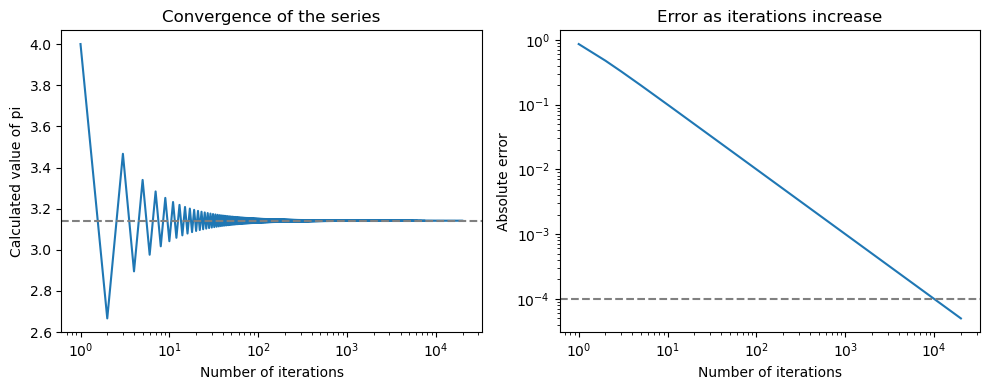

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(iteration_numbers, pi_terms)
axes[0].set_xscale("log")
axes[0].axhline(math.pi, color="gray", linestyle="--")
axes[0].set_xlabel("Number of iterations")
axes[0].set_ylabel("Calculated value of pi")
axes[0].set_title("Convergence of the series")

axes[1].plot(iteration_numbers, absolute_errors)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].axhline(reasonable_error, color="gray", linestyle="--")
axes[1].set_xlabel("Number of iterations")
axes[1].set_ylabel("Absolute error")
axes[1].set_title("Error as iterations increase")

plt.tight_layout()
plt.show()

## Interpretation and Reflection

### 1. What did you do?

I used the Madhava-Leibniz π calculation from the solution file. I changed it so that it runs for many iteration numbers and stores both the calculated value and the absolute error at every step. I also put the main calculation in a function and tested it three times.

### 2. What did you learn from your calculation?

The calculated value gets closer to π as the number of iterations increases. With the signs alternate, the estimates move above and below π. The distance from the expected value get smaller, but the improvement is also small. The errors are about 0.1 at 10 iterations, 0.01 at 100 iterations, and 0.001 at 1,000 iterations.

### 3. What does your figure mean?

The left plot shows the estimates approaching the horizontal line for `math.pi`. The right plot shows the convergence more clearly. The error falls as the iteration number increases, but it takes about ten times as many iterations to reduce the error by about a factor of ten. The calculation reaches my 0.0001 error limit at approximately 10,000 iterations.

### 4. Is more computation always better?

The more iterations, the more accurate, but at a higher cost. Reducing the error from 0.001 to 0.0001 improves precision tenfold, but also increases computation by tenfold, an equivalent trade-off. It might be more cost-effective to switch to a faster-converging formula rather than simply increasing the number of iterations.

### 5. What did you learn about programming?

I became more comfortable using a `for` loop with an `if/else` statement to build a numerical series. I also practiced storing results with lists and `.append()`. 

### 6. What was challenging?

A sign error changes whether a term is added or subtracted and gives the wrong result. It was the most confusing part. 